In [1]:
import sys
sys.path.append("../")

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from pyACC.cosmology.distances import Distances

/home/fish31/anaconda3/envs/acc-env/lib/python3.12/site-packages/numpy/_core/getlimits.py:551: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)


In [3]:
class HubbleFunction:
    # class constructor
    def __init__(self, H0, omega_m, omega_lambda, omega_rad):
        self.H0 = H0 # Hubble constant
        self.omega_m = omega_m # matter density parameter
        self.omega_lambda = omega_lambda # DE density parameter
        self.omega_rad = omega_rad # radiation density parameter

    def __call__(self, z):
        """Calculate the Hubble parameter at redshift z"""
        return self.H0 * np.sqrt(self.omega_m * (1 + z)**3 + self.omega_lambda + self.omega_rad * (1 + z)**4)

In [29]:
class Hubble_w0wa:
    # class constructor
    def __init__(self, H0, omega_m, omega_lambda, omega_rad, w0, wa):
        self.H0 = H0 # Hubble constant
        self.omega_m = omega_m # matter density parameter
        self.omega_lambda = omega_lambda # DE density parameter
        self.omega_rad = omega_rad # radiation density parameter
        self.w0 = w0 # DE equation of state at z=0
        self.wa = wa # DE equation of state slope

    def __call__(self, z):
        """Calculate the Hubble parameter at redshift z"""
        return self.H0 * np.sqrt(self.omega_m * (1 + z)**3 + self.omega_lambda * (1 + z)**(3 * (1 + self.w0 + self.wa)) * np.exp(-3 * self.wa * z / (1+z)))

QUICK CHECK

In [4]:
# Testing pyACC methods
Hf = HubbleFunction(70, 0.3, 0.7, 0.0)
D_comoving = Distances(Hf) # D_comoving instance of Distances class
D_comoving.comoving_distance(1. , 100) # Calling comoving_distance method and passing required parameters z and n_nodes

np.float64(3303.833183541017)

In [5]:
# CFR with astropy built-in method
from astropy.cosmology import FlatLambdaCDM # LambdaCDM model with no curvature
cosmo = FlatLambdaCDM(H0=70, Om0=0.3) # cosmo instance of FlatLambdaCDM class and setting required parameters H0 and Om0
# Calculating comoving distance with astropy comoving_distance method
z = 1.
dc = cosmo.comoving_distance(z) # Calling astropy method and passing required parameter z
print(dc)

3303.8288058874678 Mpc


Reproducing DESI BAO Measurements Results

In [6]:
# Calculating Dm with pyACC method for z between 0.01 and 3, 0.01 step
H_LCDM_CMB = HubbleFunction(67.14, 0.3169, 1.-0.3169, 0.0) # Flat LCDM with CMB parameters
r_d = 147.05 # sound horizon in Mpc

zz = np.linspace(0.01, 3., 300)
redshift = []
Dm_LCDM_CMB = []
for z in zz:
    redshift.append(z)
    Dc = Distances(H_LCDM_CMB) #Dc instance of Distances class
    Dm_LCDM_CMB.append(Dc.comoving_distance(z, n_nodes=100) / r_d)

In [7]:
H_LCDM_CMB_DESI = HubbleFunction(68.17, 0.3027, 1.-0.3027, 0.0) # Flat LCDM with CMB+DESI parameters
Dm_LCDM_CMB_DESI = []
for z in zz:
    Dc = Distances(H_LCDM_CMB_DESI) #Dc instance of Distances class
    Dm_LCDM_CMB_DESI.append(Dc.comoving_distance(z, n_nodes=100) / r_d)

In [30]:
H_w0waCDM_CMB_DESI = Hubble_w0wa(66.74, 0.3191, 1. - 0.3191, 0.0, -0.752, -0.86)
Dm_w0waCDM_CMB_DESI = []
for z in zz:
    Dc = Distances(H_w0waCDM_CMB_DESI)
    Dm_w0waCDM_CMB_DESI.append(Dc.comoving_distance(z, n_nodes=100) / r_d)


In [33]:
for i in range(0, len(Dm_LCDM_CMB), 1):
    Dm_LCDM_CMB_DESI[i] /= Dm_LCDM_CMB[i]
    Dm_w0waCDM_CMB_DESI[i] /= Dm_LCDM_CMB[i]
    Dm_LCDM_CMB[i] /= Dm_LCDM_CMB[i]

<function matplotlib.pyplot.show(close=None, block=None)>

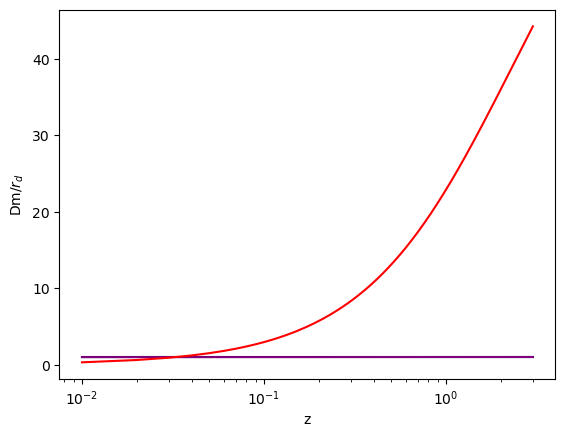

In [34]:
# Plotting
plt.semilogx(redshift, Dm_LCDM_CMB, color='black', )
plt.semilogx(redshift, Dm_LCDM_CMB_DESI, color='purple', )
plt.semilogx(redshift, Dm_w0waCDM_CMB_DESI, color='red', )
plt.xlabel("z")
plt.ylabel("Dm/"r'$r_d$')
plt.show